# Plotting postprocessed data

Example of the analysis functions of `postprocessed_analysis.py` on the timestamp `1791789186`
(postprocessing folder, `compute_keywords=['static']`): 5 result files (one per grid, $N_t$ = 1501 ... 501 at fixed $T_{max}$),
each containing 12 temperatures.

| function | what it does |
|---|---|
| `detect_job_parameters` | which parameters vary inside a file (inner), differ between files (outer) or are constant |
| `plot_gap_vs_parameter` | $|\Delta|/T_c$ vs the inner parameter, one curve per file, legend = parameter that differs between files |
| `analyze_errors_vs_grid` | gap difference and normalization / FDT errors vs $dt$ (or $T_{max}$) with fitted exponents |
| `plot_green_function_rows` | $g^R(t=-1,t')$ and $g^K(t=-1,t')$, all components, real and imaginary |
| `plot_consistency_rows` | normalization and FDT error rows at $t=-1$ vs $t'$ with printed maxima |

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('/home/filip/Git_Code/')
sys.path.append('/home/filip/Documents/Research/Superconducting_vortices/Keldysh-non-eq/psBQP-keldysh/')

from demler_tools.file_manager import path_management

import postprocessed_analysis as pa

In [2]:
# Initialize demler_tools path management
path_management.initialize(project_name='psBQP-keldysh')

timestamp ='1791963536'#'1791905534'# '1791789186'

Successfully initialized path management with following parameters:
     username:                fmarijanovic
     project name:            psBQP-keldysh
     controlling machine:     laptop
     library version:         v2.3.0-beta-8-g6d57f9e
     auto SSH transfer:       True
     default save location:   /home/filip/Documents/Research/data_files/
     LTS mount point:         /home/filip
     email domain:            phys.ethz.ch
     cluster OS:              Ubuntu
     cluster partition:       work
     SSH host file:           /home/filip/.ssh/known_hosts
     SSH key file:            /home/filip/.ssh/id_ed25519_euler
     default modules:         {'CentOS': 'gcc/8.2.0 python/3.11.2', 'Ubuntu': 'stack/2024-06 python/3.11.6'}


## Which parameters differ between the jobs?

In [3]:
detection = pa.detect_job_parameters(timestamp)

Timestamp 1791963536: 2 result file(s), indices [0, 1]
  varies inside each file (inner): amplitude
  differs between files (outer): -
  constant: FWHM = 20, critical_temperature = 1, dt = 0.0628319, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159, time_sampling = 501


## Gap vs parameter (one curve per file, legend = parameter that differs between the files)

Timestamp 1791963536: 2 result file(s), indices [0, 1]
  varies inside each file (inner): amplitude
  differs between files (outer): -
  constant: FWHM = 20, critical_temperature = 1, dt = 0.0628319, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159, time_sampling = 501
  file 0, file 0:
           amplitude       |gap|/T_c
                0.05  1.36417181e+00
                 0.1  1.34034752e+00
                0.15  1.29866364e+00
                 0.2  1.23600818e+00
                0.25  1.14667417e+00
                 0.3  1.01958827e+00
                0.35  8.31049392e-01
                 0.4  5.13472728e-01
                0.45  3.67905213e-02
                 0.5  4.39015661e-05
  file 1, file 1:
           amplitude       |gap|/T_c
                0.05  1.36418558e+00
                 0.1  1.34032027e+00
                0.15  1.29886875e+00
                 0.2  1.23678587e+00
                0.25  1.14818369e+00
                 0.3  1.02327624e+

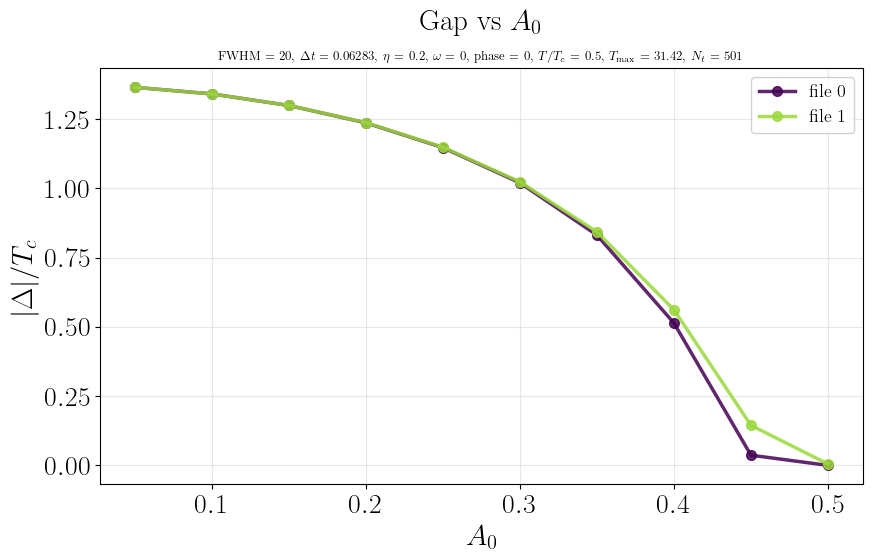

['file 0', 'file 1']


In [4]:
result = pa.plot_gap_vs_parameter(timestamp, save_plot=False)
print(result['labels'])

## Error analysis with $dt$

Gap difference to the finest grid, $g^R$ / $g^K$ normalization and FDT error at $(t,t')=(-1,-1)$ vs $dt$ for every temperature,
with the fitted exponents $p$ in error $\propto dt^p$. The $g^R$ normalization error is exactly zero at $(-1,-1)$ by construction, see the
profile plots below for the error along $t'$.

In [5]:
errors = pa.analyze_errors_vs_grid(timestamp, save_plot=False)

Timestamp 1791914110: 2 result file(s), indices [0, 1]
  varies inside each file (inner): amplitude
  differs between files (outer): -
  constant: FWHM = 20, critical_temperature = 1, dt = 0.0628319, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159, time_sampling = 501


ValueError: No grid parameter (dt or time_duration) differs between the files

## $g(t=-1,t')$ rows

The rows are saved by the `'static'` postprocessing (key `'rows'`). For older folders (like this one) the raw evolution run is used if it is
available locally; otherwise a message says what to copy or re-run. `directory_job_index` selects the file (grid), `job_index` the
temperature inside it.

In [ ]:
try:
    rows = pa.plot_green_function_rows(timestamp, directory_job_index=0, job_index=0, save_plot=False)
except FileNotFoundError as error:
    print(error)

No rows stored in postprocessed folder 1791789186 (file 0) and the raw run 1791735275 is not available locally (expected /home/filip/Documents/Research/data_files/psBQP-keldysh/simulation_results/1791735275). Either copy the raw folder from the cluster or re-run the 'static' postprocessing, which now saves the rows. (Kwargs file not found for timestamp 1791735275)


## Normalization and FDT errors at $t=-1$ vs $t'$ (maximal errors are printed)

In [ ]:
try:
    rows = pa.plot_consistency_rows(timestamp, directory_job_index=0, job_index=0, save_plot=False)
except FileNotFoundError as error:
    print(error)

No rows stored in postprocessed folder 1791789186 (file 0) and the raw run 1791735275 is not available locally (expected /home/filip/Documents/Research/data_files/psBQP-keldysh/simulation_results/1791735275). Either copy the raw folder from the cluster or re-run the 'static' postprocessing, which now saves the rows. (Kwargs file not found for timestamp 1791735275)


### Getting the rows for this timestamp

Either copy the raw folders listed in the `calculation_arguments` of the postprocessing folder from the cluster to the local data folder, or
re-run the `'static'` postprocessing on the cluster (the rows are now saved by default).

# State evolution (timestamp from `compute_keywords=['state_evolution']`)

Time series of every job in a result file: gap, current and vector potential versus $t$. Use the timestamp of the postprocessing folder
created with `'state_evolution'`; the static-equilibrium timestamp above has no time series.

In [6]:
timestamp_evolution = '1791916289'  # replace by the timestamp of the 'state_evolution' postprocessing folder

## Gap deviation, current and vector potential vs time

`gap='deviation'` shows $(|\Delta(t)|-|\Delta(0)|)/T_c$, `'relative'` divides by $|\Delta(0)|$ and `'absolute'` shows $|\Delta(t)|/T_c$.
The legend lists the parameters that differ between the jobs of the file, `job_indices` selects a subset.

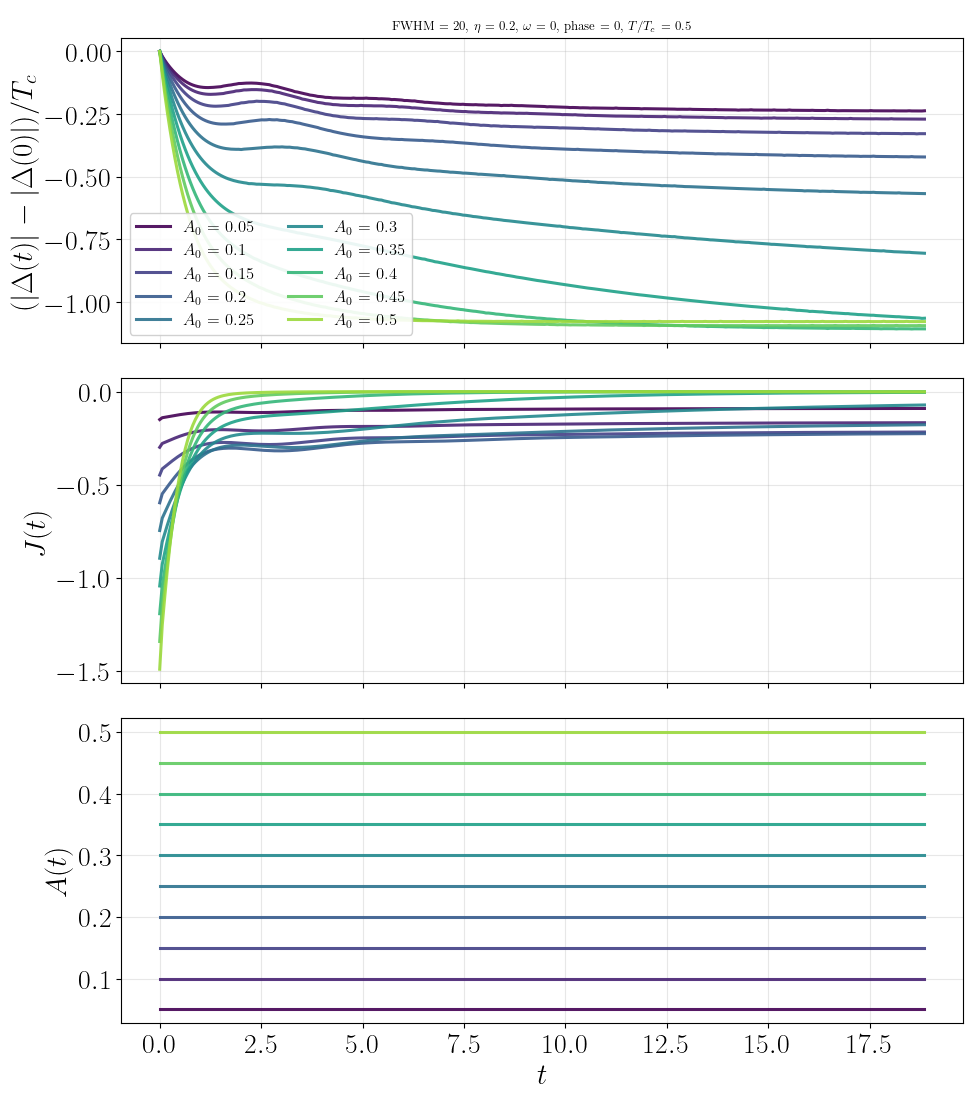

In [7]:
evolution = pa.plot_state_evolution(timestamp_evolution, directory_job_index=1, gap='deviation', save_plot=False)